<a href="https://colab.research.google.com/github/fnlopezsanz/TP_Lab_Met_Cuantitativos_Inversiones/blob/main/notebook_inversiones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(Bloque de introducción, borrador)
Pregunta: ¿Que tipos de inversiones le habrían ganado a la inflación en 2025?
(pd: LA IA ayudó a subir este notebook al GitHub)

In [242]:
#importamos librerías
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sb

In [243]:
#URL al github
URL = "https://raw.githubusercontent.com/fnlopezsanz/TP_Lab_Met_Cuantitativos_Inversiones/main/"

In [244]:
#Descargamos datos
#SPY 500
df_spy = yf.download("SPY", start="2025-01-01", end="2025-12-31", interval="1d") # La IA ayudo a como descargar datos de yfinance
#Plazo UVA
df_uva = pd.read_csv(URL + "unidad-de-valor-adquisitivo-uva-20250101-20251231.csv")
#PLazo fijo
df_fijo = pd.read_csv(URL + "tasas-de-interes-por-depositos-a-30-dias-de-plazo-en-entidades-financieras-20250101-20251231.csv")
#Inflación
df_inflacion = pd.read_csv(URL + "IPC_NACIONAL_INDEC.csv", sep=";", encoding='latin1') #Tuvimos ciertos errores al descargar este archivo, Gemini los solucionó poniendo como separador el ;, además de especificar la codificación latin1
#Valor del dolar
df_dolar = pd.read_csv(URL + "cierre_de_cotizaciones_DOLAR_2026-10-30.csv")


/tmp/ipykernel_1333/2769448920.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_spy = yf.download("SPY", start="2025-01-01", end="2025-12-31", interval="1d") # La IA ayudo a como descargar datos de yfinance
[*********************100%***********************]  1 of 1 completed


Empezaremos con la depuración de datos de todos los df, primero viendo su información y la cantidad de valores nulos que tienen (si es que hay), para luego empezar con la limpieza de datos.

*La siguiente celda usó código de IA para reescribir el índice y ordenar las fechas en una columna apate, se usó el siguiente promt a Gemini de Google Colab:
Hola, pensá que eres un analista de datos, necesitas que el df_spy pueda tener un formato que facilite la comparación de la cotización del ETF sobre el tiempo. Por lo tanto, creá un código que reescriba el índice, haciendo que las fechas sean ordenadas en una columna aparte, recordá que las fechas deben estar en formato daytime.*

In [245]:
#Evaluamos el df del SPY 500
print("Forma de df_spy", df_spy.shape)
print("\nInformación de df_spy:")
print(df_spy.info())
#Se puede observar que este df no tiene valores nulos, ya que dentro de cada columna hay 249 valores no nulos
#siendo la misma cantidad que las filas presentes en el df.
#Además, no hay tipos de datos que requieran ser cambiados

#Sin embargo, hay un problema que aparece, no existe una columna que contenga las fechas, por lo que se verá parte del df para ver
#si las fechas están presentes en algún modo
print("\nCabeza del df_spy")
print(df_spy.head())
#Si vemos la primera parte del df, se puede observar que las fechas están como índice, para lograr una mejor comparación de la variación del precio con respecto
#al tiempo se tendrá que modificar el índice y ordenar los valores de las fechas en una columna aparte.

#Código de IA
# Reestablecemos el índice para convertir las fechas de Index a una columna común
df_spy = df_spy.reset_index()

# Renombramos la columna del índice para que se llame 'Fecha'
df_spy = df_spy.rename(columns={'Date': 'Fecha'})

#Código de IA
# Dado que las columnas son índices multiples, eliminamos el segundo nivel de indices para dejar el primero (Fecha, Close, High, Low, Open, Volume)
df_spy.columns = df_spy.columns.get_level_values(0) #Selecciona directamente el primer nivel, ignorando el segundo
df_spy.columns.name = None #Elimina "price" del eje de las columnas

# Nos aseguramos de que la columna 'Fecha' esté explícitamente en formato datetime
df_spy['Fecha'] = pd.to_datetime(df_spy['Fecha'])

# Ordenamos los valores de forma ascendente según la fecha
df_spy = df_spy.sort_values(by='Fecha').reset_index(drop=True)

# Evaluamos el resultado final
print("\nNueva información de df_spy:")
print(df_spy.info())

print("\nPrimeras filas de df_spy modificado:")
display(df_spy.head())


Forma de df_spy (249, 5)

Información de df_spy:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 249 entries, 2025-01-02 to 2025-12-30
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   (Close, SPY)   249 non-null    float64
 1   (High, SPY)    249 non-null    float64
 2   (Low, SPY)     249 non-null    float64
 3   (Open, SPY)    249 non-null    float64
 4   (Volume, SPY)  249 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.7 KB
None

Cabeza del df_spy
Price            Close        High         Low        Open    Volume
Ticker             SPY         SPY         SPY         SPY       SPY
Date                                                                
2025-01-02  573.375732  579.740680  569.315484  578.034214  50204000
2025-01-03  580.544861  581.182301  575.131196  576.210038  37888500
2025-01-06  583.889160  588.145568  582.163061  584.781661  47679400
2025-01-07  577.288818  586.233

,Fecha,Close,High,Low,Open,Volume
0,2025-01-02,573.375732,579.740680,569.315484,578.034214,50204000
1,2025-01-03,580.544861,581.182301,575.131196,576.210038,37888500
2,2025-01-06,583.889160,588.145568,582.163061,584.781661,47679400
3,2025-01-07,577.288818,586.233098,575.474486,585.909439,60393100
4,2025-01-08,578.132324,579.201350,573.925001,577.357567,47304700


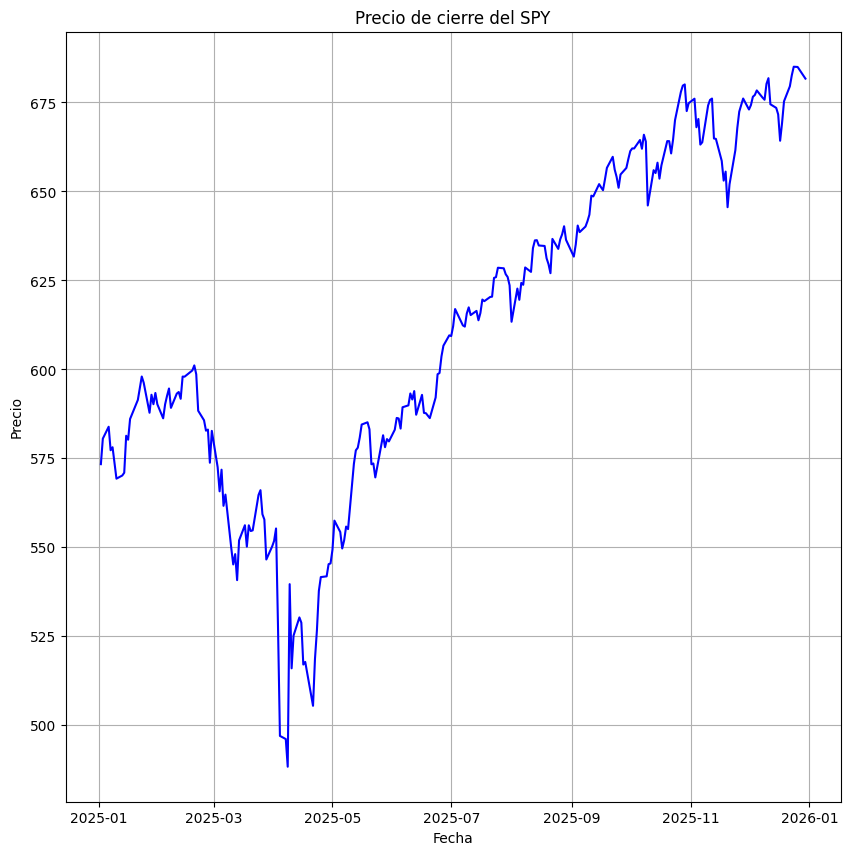

In [246]:
#Graficamos el SYP 500
plt.figure(figsize=(10,10))
sb.lineplot(x = "Fecha", y ="Close", data = df_spy, color = "blue")
plt.title("Precio de cierre del SPY")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.grid(True)
plt.show()

In [247]:
#Evaluamos el df del dolar

print("Forma de df_dolar", df_dolar.shape)
print()
print("Información de df_dolar:")
print(df_dolar.info())

#Quitamos los puntos de los miles y cambiamos la , por . para poder cambiar el type
df_dolar["Comprador"] = df_dolar["Comprador"].astype(str).str.replace(".", "", regex=False)
df_dolar["Comprador"] = df_dolar["Comprador"].str.replace(",", ".", regex=False)

df_dolar["Vendedor"] = df_dolar["Vendedor"].astype(str).str.replace(".", "", regex=False)
df_dolar["Vendedor"] = df_dolar["Vendedor"].str.replace(",", ".", regex=False)

#Corregimos los Dtype
df_dolar["Fecha"] = pd.to_datetime(df_dolar["Fecha"])
df_dolar["Comprador"] = pd.to_numeric(df_dolar["Comprador"])
df_dolar["Vendedor"] = pd.to_numeric(df_dolar["Vendedor"])


#Imprimimos las primeras primeras y las últimas 5 filas para ver las fechas del df
print()
print("Observamos las primeras 5 filas\n", df_dolar.head())
print()
print("Observamos las últimas 5 filas\n", df_dolar.tail())
print("Debemos filtrar por año")
print()

#El df tiene datos de 2010 a 2026, filtramos solo el 2025 y reiniciamos index
df_dolar = df_dolar[(df_dolar["Fecha"] >= "2025-01-01") & (df_dolar["Fecha"] <= "2025-12-31")]
df_dolar = df_dolar.reset_index()
df_dolar = df_dolar.drop(columns=["index"])

print("Observamos las primeras 5 filas del 2025\n", df_dolar.head())
print()
print("Observamos las últimas 5 filas del 2025\n", df_dolar.tail())


Forma de df_dolar (3983, 3)

Información de df_dolar:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3983 entries, 0 to 3982
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Fecha      3983 non-null   object
 1   Comprador  3983 non-null   object
 2   Vendedor   3983 non-null   object
dtypes: object(3)
memory usage: 93.5+ KB
None

Observamos las primeras 5 filas
        Fecha  Comprador  Vendedor
0 2026-10-29   1507.676  1560.669
1 2026-10-28   1507.048  1560.117
2 2026-10-27   1506.870  1559.939
3 2026-10-26   1507.257  1560.401
4 2026-10-23   1496.322  1549.767

Observamos las últimas 5 filas
           Fecha  Comprador  Vendedor
3978 2010-06-07      3.903     3.954
3979 2010-06-04      3.901     3.952
3980 2010-06-03      3.901     3.953
3981 2010-06-02      3.905     3.955
3982 2010-06-01      3.904     3.955
Debemos filtrar por año

Observamos las primeras 5 filas del 2025
        Fecha  Comprador  Vendedor
0 202

/tmp/ipykernel_1333/1106093508.py:16: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_dolar["Fecha"] = pd.to_datetime(df_dolar["Fecha"])


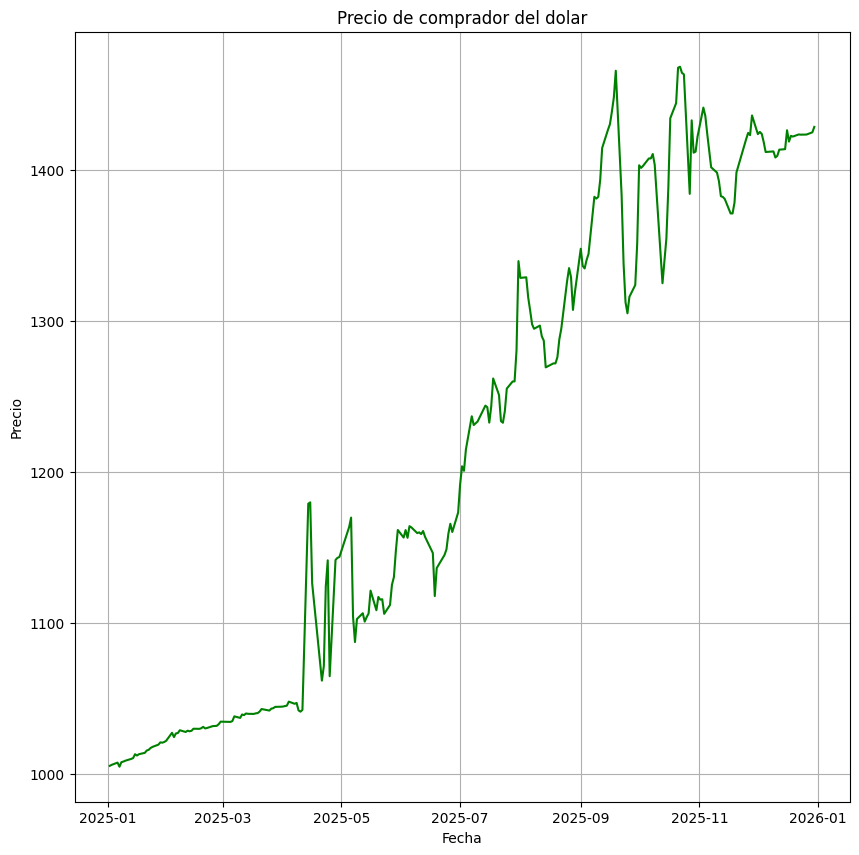

In [248]:
#Graficamos el Valor del dolar
plt.figure(figsize=(10,10))
sb.lineplot(x = "Fecha", y ="Comprador", data = df_dolar, color = "green")
plt.title("Precio de comprador del dolar")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.grid(True)
plt.show()

In [249]:
#Evaluamos el df del plazo UVA

print("Forma de df_uva", df_uva.shape)
print()
print("Información de df_uva:")
print(df_uva.info())
#En este caso también se observa que no hay valores nulos dentro del df, sin embargo, la fechas tienen como tipo object,
#esto no es lo más recomendable, por lo que el tipo que tienen los datos de la columna Fecha cambiará al tipo de daytime
#para poder comparar mejor la evolución de la tasa del plazo uva
#en distintos momentos, no hacer este paso podría llevar a errores más adelante en el notebook.
print()
df_uva["Fecha"] = pd.to_datetime(df_uva["Fecha"])
print("Invormación de df_uva con cambios:") #Como se puede ver, ahora los datos de las fechas están en daytime
print(df_uva.info())
print()
print("Cabeza de df_uva:", df_uva.head())
display(df_uva.head())

Forma de df_uva (365, 2)

Información de df_uva:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Fecha   365 non-null    object 
 1   Valor   365 non-null    float64
dtypes: float64(1), object(1)
memory usage: 5.8+ KB
None

Invormación de df_uva con cambios:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Fecha   365 non-null    datetime64[ns]
 1   Valor   365 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 5.8 KB
None

Cabeza de df_uva:        Fecha    Valor
0 2025-01-01  1301.85
1 2025-01-02  1301.85
2 2025-01-03  1303.84
3 2025-01-04  1304.84
4 2025-01-05  1304.84


,Fecha,Valor
0,2025-01-01,1301.85
1,2025-01-02,1301.85
2,2025-01-03,1303.84
3,2025-01-04,1304.84
4,2025-01-05,1304.84


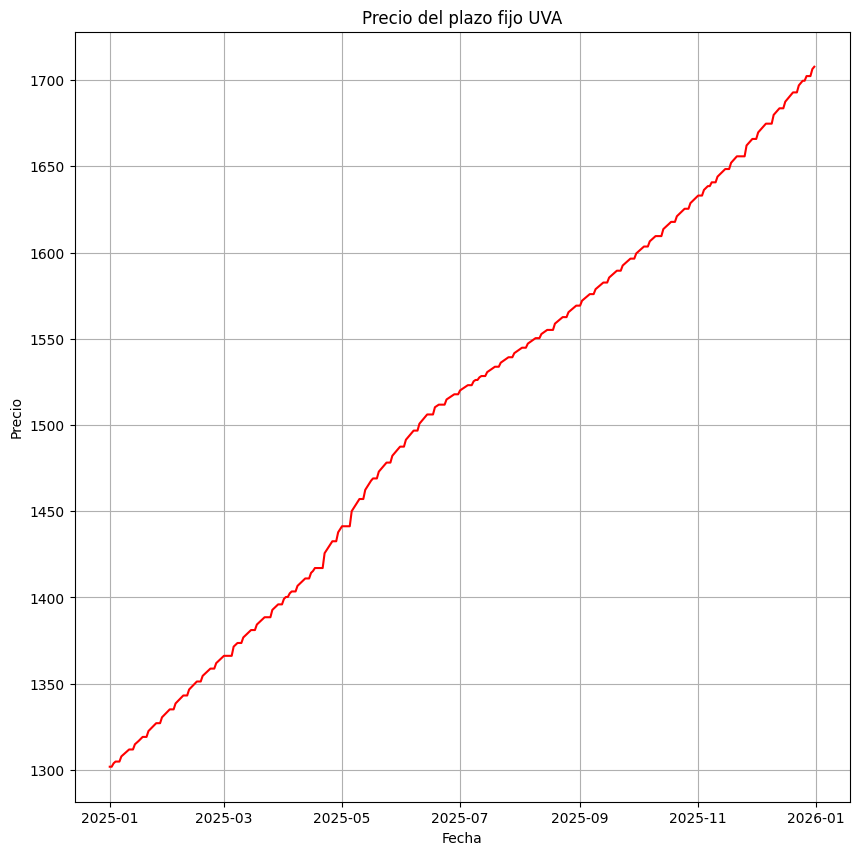

In [250]:
#Graficamos el plazo fijo UVA
plt.figure(figsize=(10,10))
sb.lineplot(x = "Fecha", y ="Valor", data = df_uva, color = "red")
plt.title("Precio del plazo fijo UVA")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.grid(True)
plt.show()

In [251]:
#Evaluamos el df del plazo fijo

print("Forma de df_fijo", df_fijo.shape)
print()
print("Información de df_fijo:")
print(df_fijo.info())
#Por las mismas razones explicadas en el caso de df_uva, se cambiará el tipo de datos de la columna Fecha a daytime
df_fijo["Fecha"] = pd.to_datetime(df_fijo["Fecha"])
print()
print("Información de df_fijo con cambios:")
print(df_fijo.info())
print()
print("Cabeza de df_fijo:", df_fijo.head())
display(df_fijo.head())

Forma de df_fijo (240, 2)

Información de df_fijo:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Fecha   240 non-null    object 
 1   Valor   240 non-null    float64
dtypes: float64(1), object(1)
memory usage: 3.9+ KB
None

Información de df_fijo con cambios:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Fecha   240 non-null    datetime64[ns]
 1   Valor   240 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 3.9 KB
None

Cabeza de df_fijo:        Fecha  Valor
0 2025-01-02  31.42
1 2025-01-03  31.80
2 2025-01-06  31.59
3 2025-01-07  31.01
4 2025-01-08  30.32


,Fecha,Valor
0,2025-01-02,31.42
1,2025-01-03,31.80
2,2025-01-06,31.59
3,2025-01-07,31.01
4,2025-01-08,30.32


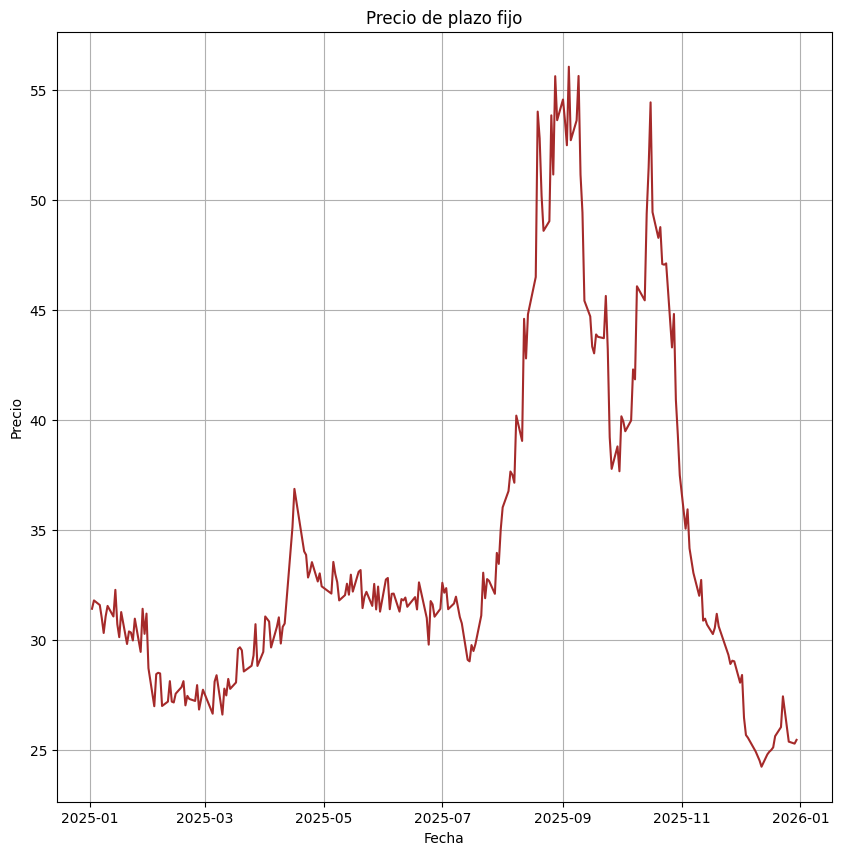

In [252]:
#Graficamos el plazo fijo tradicional
plt.figure(figsize=(10,10))
sb.lineplot(x = "Fecha", y ="Valor", data = df_fijo, color = "brown")
plt.title("Precio de plazo fijo")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.grid(True)
plt.show()

Empezamos con el procesamiento de datos, primero vemos estádisticas simples de los datos de los DataFrames para luego evaluar las métricas financieras.

In [253]:
#Análisis del SPY:
print("Día de apertura anual")
print(df_spy.loc[0])
#Como se puede ver, el precio de apertura fue de 578 dólares.
print("Estadísticas del SPY:")
print(df_spy.describe().round(2))
#También se muestra el precio de cierre, para ver como resultó la inversión al final del año.
print()
print("Día de cierre anual:")
print(df_spy.loc[248]) #último día operativo del año
#Como se puede ver, el precio de cierre del último día del año fue de un poco más de $681, por lo que la inversión
#fue rentable en términos nominales

Día de apertura anual
Fecha     2025-01-02 00:00:00
Close              573.375732
High                579.74068
Low                569.315484
Open               578.034214
Volume               50204000
Name: 0, dtype: object
Estadísticas del SPY:
                               Fecha   Close    High     Low    Open  \
count                            249  249.00  249.00  249.00  249.00   
mean   2025-07-02 20:14:27.469879552  610.84  613.96  606.99  610.64   
min              2025-01-02 00:00:00  488.38  513.19  473.94  481.21   
25%              2025-04-03 00:00:00  578.14  582.50  573.93  578.22   
50%              2025-07-03 00:00:00  612.13  613.77  609.59  613.02   
75%              2025-10-01 00:00:00  655.16  658.65  651.42  655.13   
max              2025-12-30 00:00:00  685.03  686.30  683.93  685.29   
std                              NaN   47.12   46.07   48.39   47.43   

             Volume  
count  2.490000e+02  
mean   7.243818e+07  
min    2.604870e+07  
25%    5.752900e

Viendo las estadísticas de la columna close, se observa que la media y la mediana (percentil 50) tienen valores similares, esto nos indica que la distribución del precio pudo haber sido similar a una distribución mesocúrtica. Además, se puede ver que la diferencia entre el máximo y el mínimo del precio de cierre fue un poco menos de 200 dólares lo que podría indicar que el SPY tuvo variaciones notables durante el año, y se puede confirmar con el desvió estándar de 47,12 dólares.
También se puede ver que el precio mínimo es menor que el precio iniical. Por lo que si una persona invertía en el SPY desde
inicios de 2025 esta llegaba a perder dinero en algunos puntos. Sin embargo, si miramos el precio de cierre del primer cuartil podemos indicar que es un poco mayor que el precio de apertura anual del SPY, por lo que la inversión fue rentable (en valor nominal) durante más del 75% de los días operativos en el año.
Por último, el precio máximo fue de 685 dólares, por lo que cada ETF comprado al inicio del año llegó a tener más de $100 en rentabilidad nominal.


#Análisis financiero

Ahora se va a realizar el análisis de verdad con métricas financieras para ver que tan rentable es la inversión. Se va a calcular la TNA comparando el precio inicial y el precio final. También se va a medir la inverión en períodos trimestrales, el precio que se utiliza para medir los resultados trimestrales será el precio de cierre del último día del período.
Se establece como capital inicial de la supuesta inversión 1.000.000 pesos argentinos

In [254]:
Co = 1_000_000
n = 4

#Empezamos calculando la TNA
dia_inicial = df_spy.loc[0]
dia_final = df_spy.loc[248]

precio_0 = dia_inicial["Open"]
precio_1 = dia_final["Close"]

TNA_spy = (precio_1 / precio_0) - 1

#Calculamos la tasa efectiva en el caso hipotético que el cedear tuvo un comportamiento similar al de la fórmula escrita
TET_spy = TNA_spy * (90/365) #Pasamos a la tasa efectiva trimestral, eso significa TET

#Calculamos el valor futuro usando la tasa efectiva
Cn_spy = Co * (1 + TET_spy)**n

#Vemos resutlados
print("Sin comisiones ni IVA")
print("TNA: ", TNA_spy * 100, "%")
print("TET: ", TET_spy * 100, "%")
print("Capital final: $", round(Cn_spy, 2))
print("Ganancia nominal : ", round(Cn_spy - Co, 2))

Sin comisiones ni IVA
TNA:  17.931695111268418 %
TET:  4.421513863052487 %
Capital final: $ 1188940.01
Ganancia nominal :  188940.01


Ahora se van a incluir comisiones, IVA y derechos de mercado BYMA para el cálculo financiero. En este caso se estableció una comisión del 0,5%, que es similar a la que cobra el broker de invertironline. La IA ayudó a investigar los gastos que hay a la hora de invertir en la bolsa.
Las fuentes que se utilizaron para extraer estos datos son:

-rankia.com.ar (comisiones de invertir online)

-BYMA (derechos de mercado BYMA)

In [255]:
comision = 0.005
iva = comision*0.21 #Solo se aplica el iva a la comisión, no al capital invertido
derecho = 0.0005*0.21 #Acá también se aplica el iva al derecho

Co_invertido_spy = Co * (1 - comision - iva - derecho)
#Capital final si se mantiene la inversión en SPY
Cn_total_spy_mantenido = Co_invertido_spy * (1 + TET_spy)**n
#Capital final si se estrae el dinero
Cn_total_spy = Cn_total_spy_mantenido * (1 - comision - iva - derecho)
#Gastos por invertir
gastos_spy = Cn_spy - Cn_total_spy
#Ganancias
ganancia_manteniendo = Cn_total_spy_mantenido - Co #Se mantiene la inversión
ganancia = Cn_total_spy - Co #Se vende el ETF

print("Capital final conservando el ETF: $", Cn_total_spy_mantenido)
print("Capital final vendiendo el ETF: $", Cn_total_spy)
print("Ganancia final conservando el ETF: $", ganancia_manteniendo)
print("Ganancia final vendiendo el ETF: $", ganancia)
print("Gastos de la inversión: $", Cn_spy - Cn_total_spy)

Capital final conservando el ETF: $ 1181622.0802098517
Capital final vendiendo el ETF: $ 1174349.19630616
Ganancia final conservando el ETF: $ 181622.08020985173
Ganancia final vendiendo el ETF: $ 174349.19630615995
Gastos de la inversión: $ 14590.809640292078


1181622.0802098517
1181622.0802098517
0.0


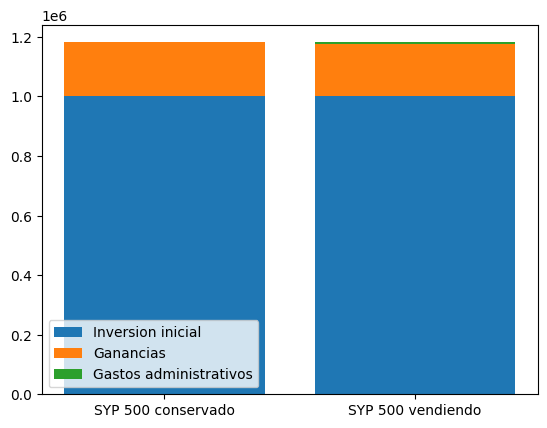

In [256]:
#Observamos la composición de los resultados del SYP 500

NombresBarras = ["SYP 500 conservado", "SYP 500 vendiendo"]
InversionInicial = [Co,Co]
InversionGanancias = [ganancia_manteniendo, ganancia]
gastos_venta = Cn_total_spy_mantenido - Cn_total_spy

plt.bar(NombresBarras, InversionInicial, label = "Inversion inicial")
plt.bar(NombresBarras, InversionGanancias, label = "Ganancias",bottom = InversionInicial)
plt.bar("SYP 500 vendiendo", gastos_venta, label = "Gastos administrativos", bottom = InversionInicial[1] + InversionGanancias[1])
plt.legend()

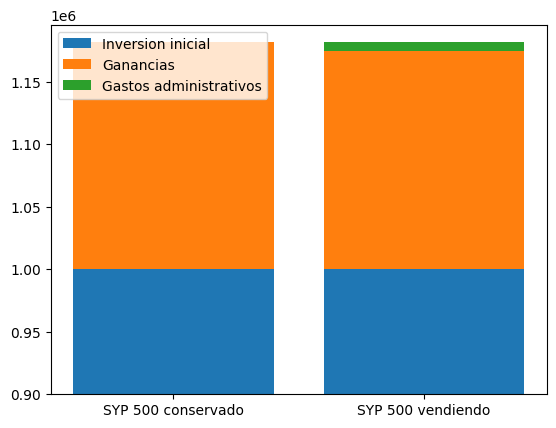

In [265]:
#Observamos la composición de los resultados del SYP 500 comenzando el eje 900000
base = 900000
NombresBarras = ["SYP 500 conservado", "SYP 500 vendiendo"]
InversionInicial_corto = [Co-base,Co-base]
InversionGanancias = [ganancia_manteniendo, ganancia]
gastos_venta = Cn_total_spy_mantenido - Cn_total_spy

plt.bar(NombresBarras, InversionInicial_corto, label = "Inversion inicial", bottom = base)
plt.bar(NombresBarras, InversionGanancias, label = "Ganancias",bottom = InversionInicial)
plt.bar("SYP 500 vendiendo", gastos_venta, label = "Gastos administrativos", bottom = InversionInicial[1] + InversionGanancias[1])
plt.legend()

#Análisis financiero

En este análisis evaluamos qué pasaría si destinamos un capital inicial de $1.000.000 a comprar dólares el primer día hábil del año y los vendemos en la última rueda del período.

In [257]:
#El banco nos vende dolares el primer día habil del año, en nuestra tabla es el último registro
CantDolaresVendedor = Co/df_dolar["Vendedor"].iloc[-1]
print("Cantidad de dólares comprados el primer día del año: ", CantDolaresVendedor)

#Compramos pesos el último día habil del año
CantDolaresComprador = CantDolaresVendedor*df_dolar["Comprador"][0]
print(CantDolaresComprador)

#Es la ganancia en valores absolutos
GananciasDolares = CantDolaresComprador - Co
print("Ganancia en dólares: ", GananciasDolares)

Cantidad de dólares comprados el primer día del año:  941.7712268171241
1345370.1113832833
Ganancia en dólares:  345370.1113832833


#Comparación de inversiones

Comparamos los resultados de las inversiones

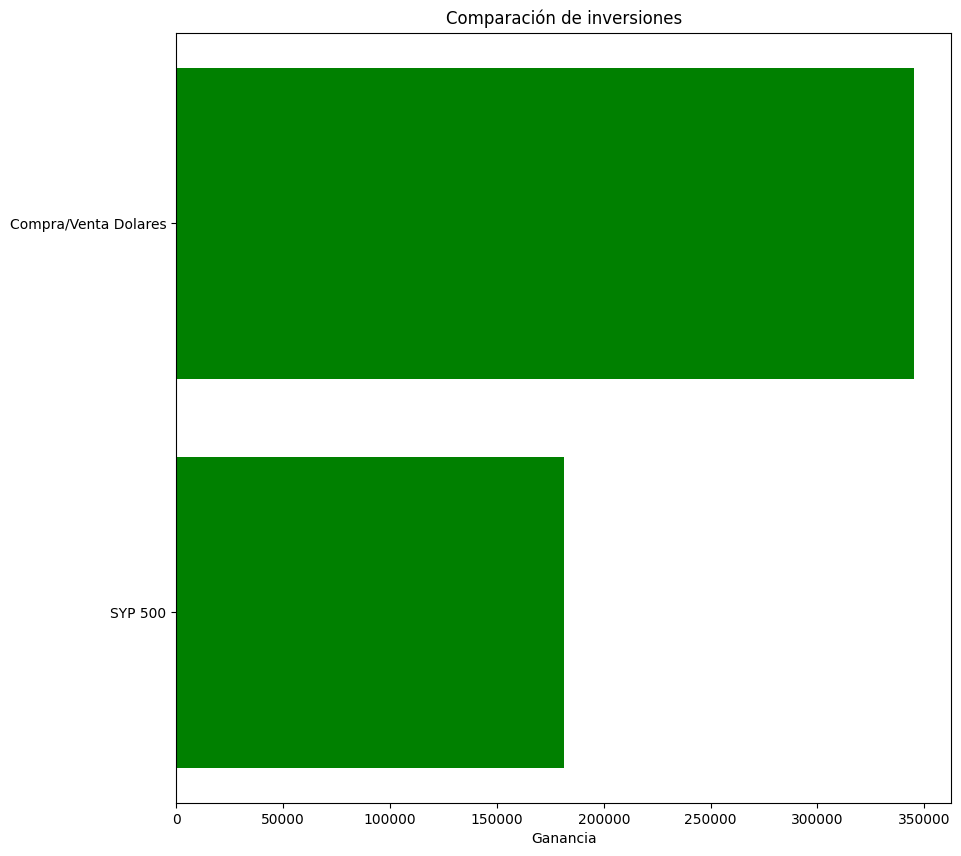

In [258]:
from numpy._core.defchararray import title
plt.figure(figsize=(10,10))
NombreInversiones = ["SYP 500", "Compra/Venta Dolares"]
ValorInversiones = [ganancia_manteniendo, GananciasDolares]
plt.barh(NombreInversiones, ValorInversiones, color = "green")
plt.title("Comparación de inversiones")
plt.xlabel("Ganancia")
plt.show()